Load data

In [4]:
from pathlib import Path
import sys


PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR))

In [5]:
from datasets import load_from_disk

data_path = "../data"

dataset = load_from_disk(data_path)
train_split = dataset["train_clean_100"]
test_split = dataset["test_clean"]

print(f"Train:\n"+str(train_split))
print(f"Test:\n"+str(test_split))

Train:
Dataset({
    features: ['sex', 'subset', 'id', 'audio', 'transcript', 'words', 'phonemes'],
    num_rows: 28538
})
Test:
Dataset({
    features: ['sex', 'subset', 'id', 'audio', 'transcript', 'words', 'phonemes'],
    num_rows: 2620
})


Analysis

Unique labels: 2


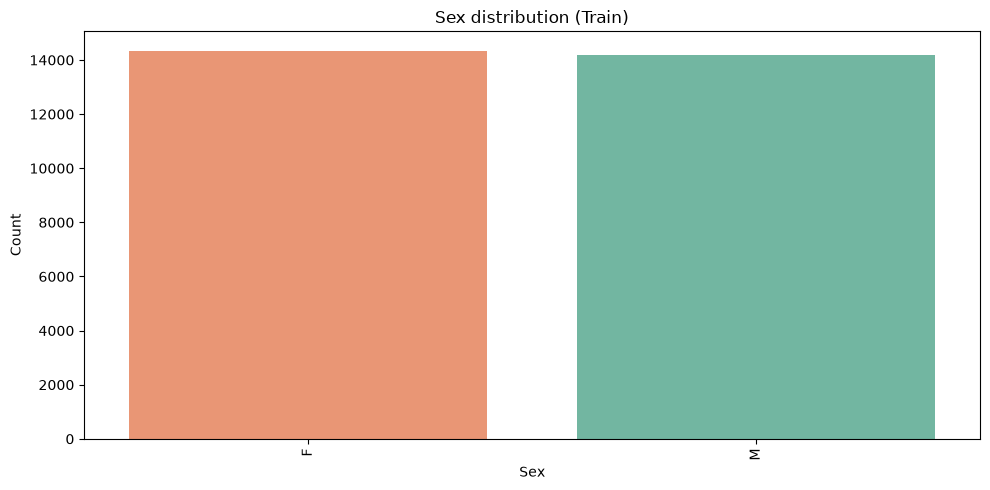

Unique labels: 2


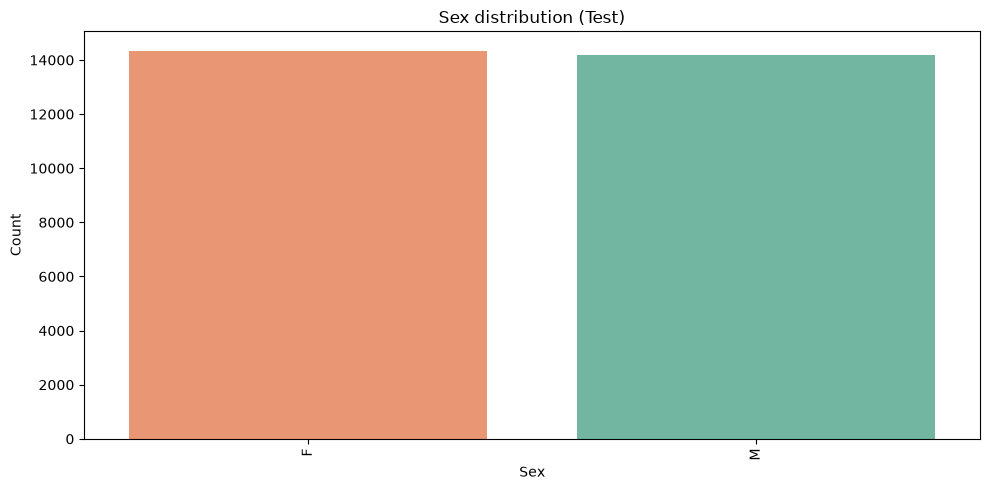

Unique labels: 70


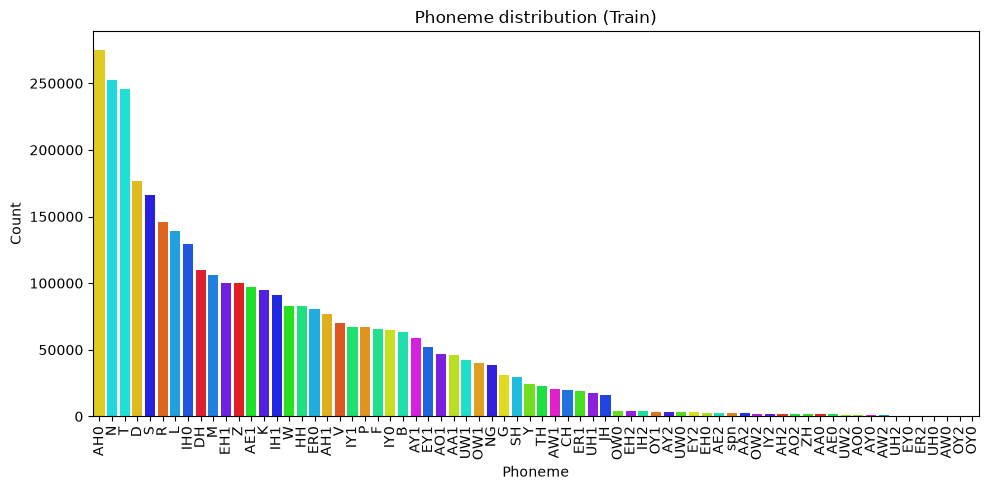

Unique labels: 69


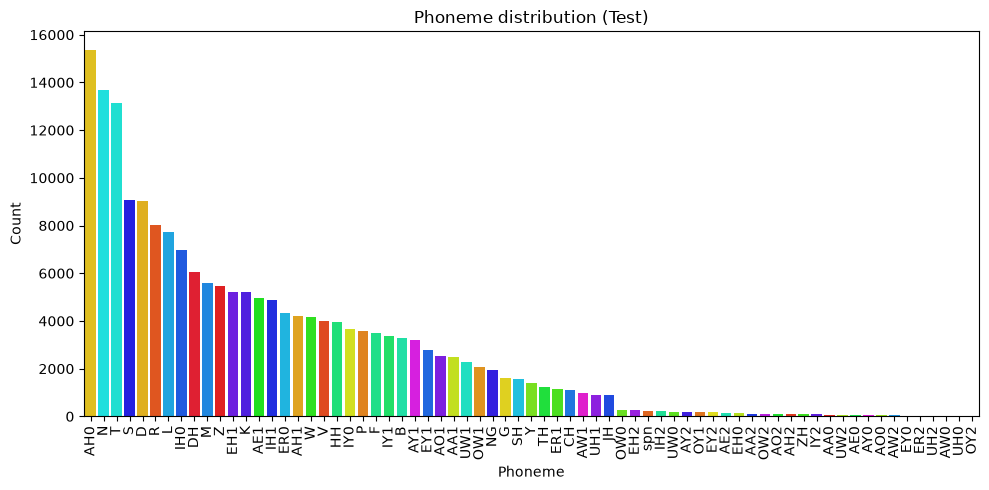

Unique labels: 40


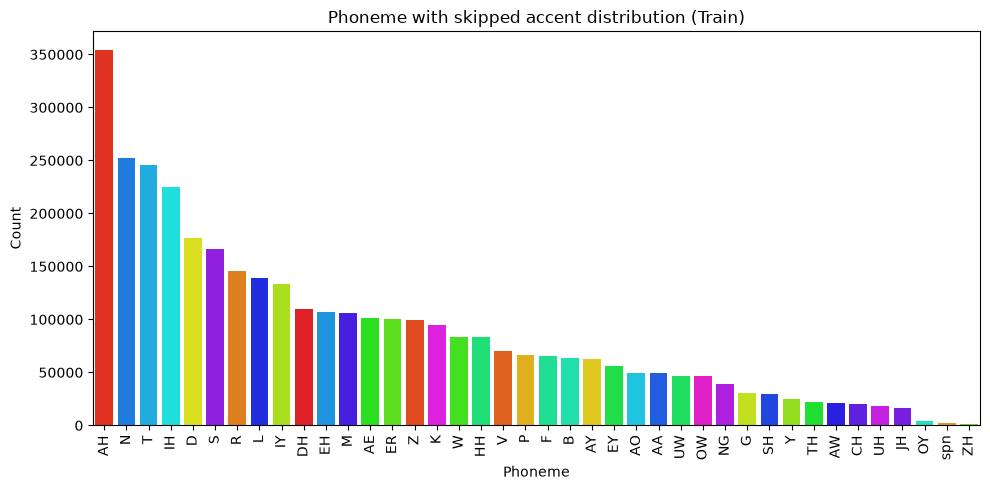

Unique labels: 40


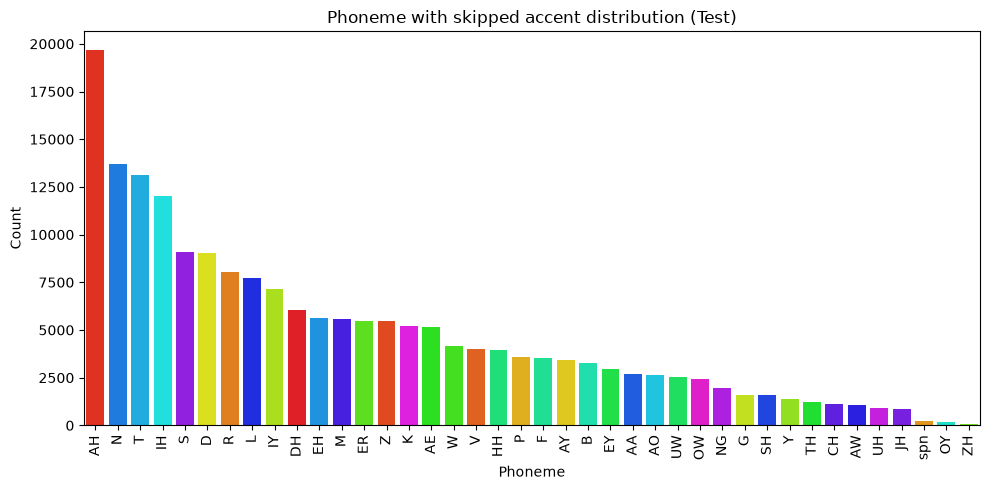

Unique labels: 15


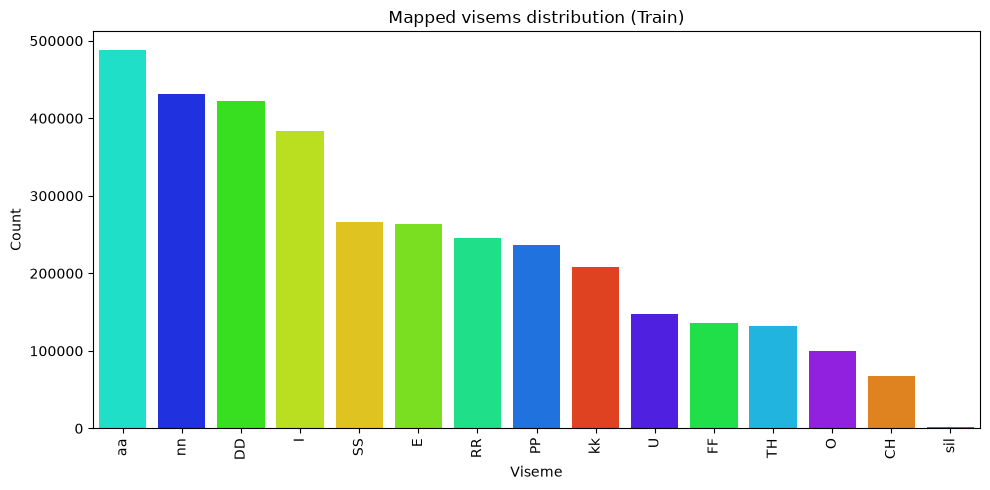

Unique labels: 15


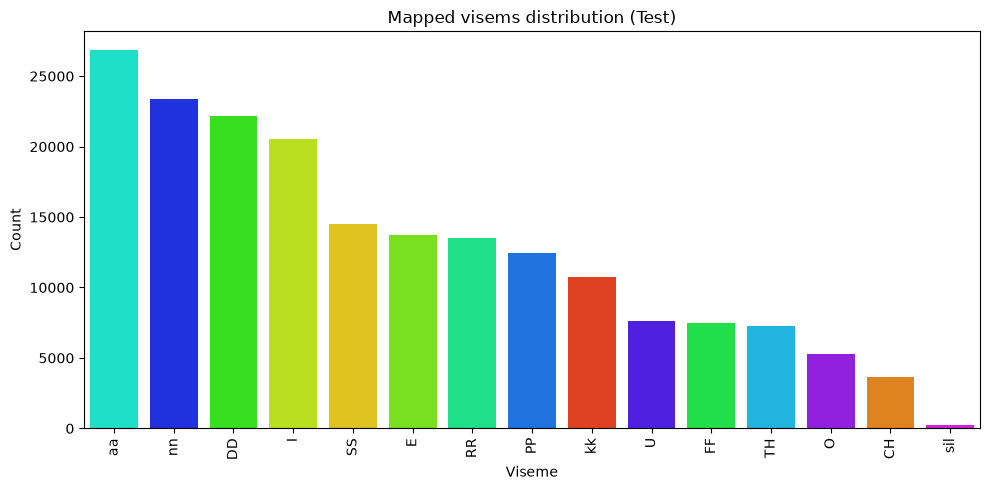

In [6]:
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns

from utils.dataset_helpers import phoneme_to_viseme, yield_phonemes, yield_phonemes_without_accent, yield_visemes

def show_value_distribution(data, title, xlabel, ylabel):
    counts = Counter(data)
    sorted_items = counts.most_common()
    
    labels = [item[0] for item in sorted_items]
    values = [item[1] for item in sorted_items]

    plt.figure(figsize=(10, 5))
    print(f"Unique labels: {len(labels)}")

    unique_labels = set(labels)
    palette_name = "Set2" if len(unique_labels) <= 8 else "gist_rainbow"

    colors = sns.color_palette(palette_name, n_colors=len(unique_labels))
    palette =  dict(zip(unique_labels, colors))
    
    sns.barplot(x=labels,y=values,
        hue=labels, hue_order = labels, palette=palette,
        legend=False
    )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()




show_value_distribution(train_split["sex"], "Sex distribution (Train)", "Sex", "Count")
show_value_distribution(train_split["sex"], "Sex distribution (Test)", "Sex", "Count")

show_value_distribution(yield_phonemes(train_split), "Phoneme distribution (Train)", "Phoneme", "Count")
show_value_distribution(yield_phonemes(test_split), "Phoneme distribution (Test)", "Phoneme", "Count")

show_value_distribution(yield_phonemes_without_accent(train_split), "Phoneme with skipped accent distribution (Train)", "Phoneme", "Count")
show_value_distribution(yield_phonemes_without_accent(test_split), "Phoneme with skipped accent distribution (Test)", "Phoneme", "Count")

show_value_distribution(yield_visemes(train_split), "Mapped visems distribution (Train)", "Viseme", "Count")
show_value_distribution(yield_visemes(test_split), "Mapped visems distribution (Test)", "Viseme", "Count")